# Calculate `VPD` (2004-2026.09)

**notebook version**: `4` (23 Oct 2026)

## ℹ️ About this notebook

Computes vapour pressure deficit `VPD` from the two products that precede it, and stores it to the
external data folder. No download, no gap-filling: `02` and `04` must be run first.

`VPD` follows from `TA` and `RH` by formula. Both inputs are complete, so **`VPD` is computed for
every record** and no model runs here. Both inputs come from **one probe at 47 m**, which changed
twice: from a Rotronic MP101A to a Campbell CS215 on 21 January 2016, and to a Campbell HygroVUE10
on 5 June 2026. Notebooks `02` and `04` each export the measured series and a homogenised one that
puts every probe era onto one level. `VPD` is computed on **both bases** and both are exported, on
the pattern of `02`, `04`, `08` and `09`:

- `VPD_T1_47_1` — from the measured pair, `TA_T1_47_1_gfXG` and `RH_T1_47_1`. This is the `VPD`
  the probe reported. It is the series that matches the measured `TA` and `RH` used as biomet input
  to EddyPro and as drivers in the flux processing chain. It steps where the probe changed.
- `VPD_T1_47_1_HOMOGENIZED` — from the homogenised pair, `TA_T1_47_1_HOMOGENIZED_gfXG` and
  `RH_T1_47_1_HOMOGENIZED`. Use it for anything that crosses January 2016 or June 2026.
- `FLAG_VPD_T1_47_1_ISFILLED` — what each record was computed from; `0` = measured `TA` **and**
  measured `RH`, `>0` = one input was gap-filled or reconstructed (see `FLAG_LEGEND`). The
  homogenised inputs are filled at the same records as the measured ones, so this flag describes
  both value columns.
- `FLAG_VPD_T1_47_1_SOURCE` — which probe, and which state of it, stands behind the record (the
  `SOURCE` flag of `02` and `04`, carried over unchanged).

**Changes against notebook version `3`.** Version `3` exported one column, computed from the
homogenised `TA` and the measured `RH`, because `04` exported no homogenised `RH` at the time. That
mixed basis corrected the temperature term and left the humidity term, and its step at 2016 was the
largest of the bases scored below. `04` now exports a homogenised `RH`, so the mixed basis is
computed here only as a diagnostic and is not exported. The column name `VPD_T1_47_1` now stands for
the measured pair, as `TA_T1_47_1_gfXG` and `RH_T1_47_1` do in their products.

The section on the probe changes scores the three bases against MeteoSwiss Lägern, at January 2016
and at June 2026, and says which of the two comparisons is an independent test.

***

## 📇 Data sources

All inputs are parquet files in the external data folder, written by earlier notebooks of this
stage or by `10_REFERENCE/`. Nothing is read from the database here.

| file | column used | from | completeness |
|---|---|---|---|
| `02_METEO_TA_GAPFILLED_2004-2026.09` | `TA_T1_47_1_gfXG` | notebook `02` | complete |
| `02_METEO_TA_GAPFILLED_2004-2026.09` | `TA_T1_47_1_HOMOGENIZED_gfXG` | notebook `02` | complete |
| `02_METEO_TA_GAPFILLED_2004-2026.09` | `FLAG_TA_T1_47_1_ISFILLED` | notebook `02` | complete |
| `02_METEO_TA_GAPFILLED_2004-2026.09` | `FLAG_TA_T1_47_1_SOURCE` | notebook `02` | complete |
| `04_METEO_RH_CORRECTED_2004-2026.09` | `RH_T1_47_1` | notebook `04` | complete |
| `04_METEO_RH_CORRECTED_2004-2026.09` | `RH_T1_47_1_HOMOGENIZED` | notebook `04` | complete |
| `04_METEO_RH_CORRECTED_2004-2026.09` | `FLAG_RH_T1_47_1_MISSING` | notebook `04` | complete |
| `04_METEO_RH_CORRECTED_2004-2026.09` | `FLAG_RH_T1_47_1_SOURCE` | notebook `04` | complete |
| `MeteoSwiss_LAE_30MIN_2004-2026.09` | `TA_LAE_MS`, `RH_LAE_MS` | `10_REFERENCE/` | reference only |

The input flags are read as well as the values: they are what makes the provenance of each computed
`VPD` knowable. Without them every computed record would look equally measured.

## ⏱️ Timestamp convention

Every input file already carries a sanitised, continuous 30MIN `TIMESTAMP_MID` index in local time,
produced by the `TimestampSanitizer` call in the notebook that wrote it. This notebook does not
shift, resample or geolocate anything: it asserts that the two indices agree and computes `VPD` on
them as they are.

***

## ⚙️ Settings

### Data settings

In [1]:
REQUIRED_TIME_RESOLUTION = '30min'  # Expected resolution of the input files; asserted below

TARGET = "VPD_T1_47_1"                    # from the measured TA and RH
TARGET_HOM = "VPD_T1_47_1_HOMOGENIZED"    # from the homogenised TA and RH

# Last record (TIMESTAMP_MID). The file names say 2026.09; the inputs and the export are asserted
# to end here.
PERIOD_END = '2026-09-30 23:45:00'
# 2026 ends in September, so statistics that compare calendar years use years up to this one only.
LAST_FULL_YEAR = 2025

SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389   # CH-LAE
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # local time UTC+01:00 (CET), the convention of every input

# Inputs: products of the earlier notebooks of this stage, in the external data folder.
# There is no database download in this notebook.
TA_FILE = "02_METEO_TA_GAPFILLED_2004-2026.09"
TA_COL = "TA_T1_47_1_gfXG"
TA_HOM_COL = "TA_T1_47_1_HOMOGENIZED_gfXG"
TA_FLAGCOL = "FLAG_TA_T1_47_1_ISFILLED"
TA_SOURCECOL = "FLAG_TA_T1_47_1_SOURCE"

RH_FILE = "04_METEO_RH_CORRECTED_2004-2026.09"
RH_COL = "RH_T1_47_1"
RH_HOM_COL = "RH_T1_47_1_HOMOGENIZED"
RH_FLAGCOL = "FLAG_RH_T1_47_1_MISSING"
RH_SOURCECOL = "FLAG_RH_T1_47_1_SOURCE"
RH_FLAG_RECONSTRUCTED = 3      # notebook 04: reconstructed from NABEL at 49 m
RH_FLAG_RECONSTRUCTED_LAE = 4  # notebook 04: reconstructed from MeteoSwiss Laegern at 2.5 km

# Reference: MeteoSwiss Laegern, 2.5 km from the tower, stored on TIMESTAMP_END. It carries both
# TA and RH, so a reference VPD follows from the same formula. Addressed by path, so a move breaks
# this read.
REFPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet")
REFCOL_TA = "TA_LAE_MS"
REFCOL_RH = "RH_LAE_MS"

# The two probe changes, from notebooks 02 and 04. The acquisition change of January 2016: the last
# record of the analog era and the first of the SDI-12 era are 20 days apart, and 2016 belongs to
# neither era. The HygroVUE10 sample of 02 and 04 starts on HV_FIT_START, the day after its SDI-12
# configuration change, and is compared with the normal CS215 (code 0) on the same calendar dates of
# HV_CS215_YEARS. Both values are declared in 02 and repeated here, not read from it.
ACQUISITION_CHANGE = '2016-01-21 14:15:00'
BREAK_YEAR = 2016
HV_START = '2026-06-05 11:45:00'
HV_FIT_START = '2026-06-12 00:00:00'
HV_CS215_YEARS = [2022, 2023, 2024]

# Output: data files live in the external (untracked) data folder, with the same
# numeric prefix as this notebook.
OUTNAME = "07_METEO_VPD_2004-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# Plausible VPD at this site, in kPa. VPD is zero at saturation and cannot be negative; the upper
# bound is generous (the record maximum is around 4 kPa) and only has to catch a unit or formula
# error, which would be off by a factor of 10 (hPa) or more.
VPD_PLAUSIBLE_KPA = (0.0, 10.0)

### Imports

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme('notebook')

import diive as dv

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-23 14:26:58
diive version: v0.93.0


In [3]:
# Captions. Every table and every figure in this notebook carries one, so that a reader meeting a
# number in the rendered page can tell what it is without reading the code that produced it.
# Defined here, above the first cell that calls either. Copied as-is from notebook 03.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')

In [4]:
# Result flags. VPD is DERIVED and, since notebooks 02 and 04 export complete TA and RH, it is
# COMPUTED for every record -- no VPD model runs here, so there are no modelled flags (1/2/4).
#
# A computed record still need not rest on two measurements: notebook 02 may have gap-filled the TA,
# or notebook 04 may have reconstructed the RH (from NABEL, or from MeteoSwiss Laegern). Those are
# not measurements, so they must not read 0. The homogenised TA and RH are filled at the same
# records as the measured ones, so one flag describes both VPD columns.
#
# The 01-03 convention holds: 0 means measured and nothing else, so a downstream `flag == 0` filter
# stays conservative.
FLAG_LEGEND = {
    0: '0 = computed from measured TA and measured RH',
    5: '5 = computed from measured RH and gap-filled TA',
    6: '6 = computed from RH reconstructed from NABEL at 49 m (TA measured or gap-filled)',
    7: '7 = computed from RH reconstructed from MeteoSwiss Laegern at 2.5 km (TA measured or gap-filled)',
}
# Every VPD record follows from the formula -- all flags are "computed" flags.
COMPUTED_FLAGS = (0, 5, 6, 7)

# Probe and probe state behind each record, carried over from notebooks 02 and 04 unchanged. TA and
# RH come from one probe, so their SOURCE flags are the same flag; that is asserted below rather than
# taken on trust, and this legend is theirs.
SOURCE_LEGEND = {
    0: '0 = Campbell CS215 on SDI-12 (from 2016-01-21), the reference level of both homogenisations',
    1: '1 = Rotronic MP101A, single-ended analog (to 2015-12-31)',
    2: '2 = acquisition changeover, probe generation undetermined',
    3: '3 = before the tower record begins',
    4: '4 = Campbell HygroVUE10 (from 2026-06-05)',
    5: '5 = half-hour in which the probe was handled or swapped, removed and reconstructed upstream',
    6: '6 = CS215 after the probe was handled on 2025-05-16',
    7: '7 = CS215 with excess daytime heating (2024-10-22 to 2025-05-16)',
}
# The CS215 states. 04 copies RH unchanged in all of them, which the calculation below asserts.
CS215_STATES = (0, 5, 6, 7)

### Helper functions

Three helpers, each with the job of failing loudly rather than quietly doing nothing:

- `load_product()` reads one of the input files and **refuses** anything whose index is not a
  continuous, duplicate-free 30MIN series or that is missing the columns asked for. Every later
  step aligns three files on a shared index, and a silently mis-shaped input would produce a
  `VPD` full of `NaN` that still had the right length.
- `short_gap_mask()` selects whole gap runs no longer than a limit. Same helper as notebook `02`.
- `check_vpd_range()` is the physical guard on the result, used twice: on the computed `VPD` and
  again on the exported series.

In [5]:
def load_product(filename: str, columns: list[str]) -> pd.DataFrame:
    """Load one stage-10 product and verify it is usable as an input here.

    Raises rather than returning a frame that would quietly poison the merge: missing columns, a
    non-30MIN index, duplicate timestamps or an index with holes all stop the notebook.
    """
    filepath = Path(OUTPATH) / f"{filename}.parquet"
    if not filepath.is_file():
        raise FileNotFoundError(
            f"{filepath} does not exist. Run the notebook that produces it before this one.")

    df = dv.load_parquet(filepath=str(filepath))

    missing = [c for c in columns if c not in df.columns]
    if missing:
        raise ValueError(f"{filename}: expected column(s) {missing}, found {list(df.columns)}.")
    if df.index.duplicated().any():
        raise ValueError(f"{filename}: {int(df.index.duplicated().sum())} duplicate timestamps.")

    steps = df.index.to_series().diff().dropna().unique()
    expected = pd.Timedelta(REQUIRED_TIME_RESOLUTION)
    if len(steps) != 1 or steps[0] != expected:
        raise ValueError(
            f"{filename}: index is not a continuous {REQUIRED_TIME_RESOLUTION} series "
            f"(found step(s) {list(steps)}).")

    out = df[columns].copy()
    print(f"  {filename:<38} {out.index[0]} -> {out.index[-1]}  ({len(out):,} records)")
    return out


def short_gap_mask(series: pd.Series, limit: int) -> pd.Series:
    """True where `series` is missing AND its whole gap is at most `limit` records long.

    Whole runs are selected explicitly. Using pandas' `interpolate(limit=)` instead would fill
    the first `limit` records of a long gap as well, which is not wanted: those values would sit
    on a straight line spanning the entire gap.
    """
    missing = series.isna()
    run_length = missing.groupby((~missing).cumsum()).transform('sum')
    return missing & (run_length <= limit)


def check_vpd_range(series: pd.Series, label: str) -> None:
    """Assert that every value present is plausible VPD in kPa.

    A formula slip or a unit mix-up (hPa instead of kPa) shows up here as a factor of 10, and a
    negative value means either an RH above 100% survived upstream or a model prediction was not
    clipped.
    """
    lo, hi = VPD_PLAUSIBLE_KPA
    values = series.dropna()
    if values.empty:
        raise ValueError(f"{label}: no values at all.")
    if values.min() < lo or values.max() > hi:
        raise ValueError(
            f"{label}: range {values.min():.3f}..{values.max():.3f} kPa is outside the plausible "
            f"{lo}..{hi} kPa. VPD is ~0-4 kPa here; a factor of 10 means hPa.")
    print(f"  {label:<34} n={len(values):>7,}  "
          f"median {float(values.median()):.3f}  range {values.min():.3f}..{values.max():.3f} kPa")

#### The guards actually guard

Both `load_product()` and `check_vpd_range()` can only earn their place if their failure path
works, so it is exercised here. Each of these must raise. If this cell prints anything other than
caught exceptions, do not trust the rest of the notebook.

In [6]:
# 1. A column that does not exist must be refused, not silently dropped.
try:
    load_product(TA_FILE, [TA_COL, 'NO_SUCH_COLUMN'])
    raise AssertionError("load_product accepted a missing column - the guard is broken.")
except ValueError as exc:
    print(f"OK, raised as intended:\n  {exc}\n")

# 2. VPD in hPa (i.e. 10x too large) must be refused.
try:
    check_vpd_range(pd.Series([5.0, 12.0, 30.0]), 'VPD in hPa by mistake')
    raise AssertionError("check_vpd_range accepted hPa-magnitude values - the guard is broken.")
except ValueError as exc:
    print(f"OK, raised as intended:\n  {exc}\n")

# 3. A negative VPD must be refused.
try:
    check_vpd_range(pd.Series([0.4, -0.01, 1.2]), 'VPD with a negative value')
    raise AssertionError("check_vpd_range accepted a negative VPD - the guard is broken.")
except ValueError as exc:
    print(f"OK, raised as intended:\n  {exc}")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet (0.043 seconds).

OK, raised as intended:
  02_METEO_TA_GAPFILLED_2004-2026.09: expected column(s) ['NO_SUCH_COLUMN'], found ['TA_T1_47_1_gfXG', 'FLAG_TA_T1_47_1_ISFILLED', 'TA_T1_47_1_HOMOGENIZED_gfXG', 'FLAG_TA_T1_47_1_SOURCE'].

OK, raised as intended:
  VPD in hPa by mistake: range 5.000..30.000 kPa is outside the plausible 0.0..10.0 kPa. VPD is ~0-4 kPa here; a factor of 10 means hPa.

OK, raised as intended:
  VPD with a negative value: range -0.010..1.200 kPa is outside the plausible 0.0..10.0 kPa. VPD is ~0-4 kPa here; a factor of 10 means hPa.


***

## ⬇️ Load inputs

No database connection is needed. The three files below are read from the external data folder,
each of them the output of an earlier notebook in this stage.

In [7]:
print("Loading stage-10 products:")
ta_in = load_product(TA_FILE, [TA_COL, TA_HOM_COL, TA_FLAGCOL, TA_SOURCECOL])
rh_in = load_product(RH_FILE, [RH_COL, RH_HOM_COL, RH_FLAGCOL, RH_SOURCECOL])

# Both files claim PERIOD_END in their names.
for _label, _df in [('TA', ta_in), ('RH', rh_in)]:
    assert _df.index[-1] == pd.Timestamp(PERIOD_END), (
        f"the {_label} product ends at {_df.index[-1]}, not at PERIOD_END {PERIOD_END}")

Loading stage-10 products:


> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet (0.013 seconds).

  02_METEO_TA_GAPFILLED_2004-2026.09     2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)


> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\04_METEO_RH_CORRECTED_2004-2026.09.parquet (0.013 seconds).

  04_METEO_RH_CORRECTED_2004-2026.09     2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)


### Align on one index

The three files are expected to cover the same period, but that is asserted rather than assumed.
The working index is their **intersection**, so a future input with a shorter record shortens the
product instead of filling the difference with `NaN` that would later be modelled as if it were a
genuine gap.

In [8]:
common_index = ta_in.index.intersection(rh_in.index)
common_index.name = ta_in.index.name

for _label, _df in [('TA', ta_in), ('RH', rh_in)]:
    _dropped = len(_df) - len(common_index)
    print(f"{_label:<6} {len(_df):>7,} records, {_dropped:>5,} outside the common index")
assert len(common_index) > 0, "the two inputs do not overlap at all"

df = pd.DataFrame(index=common_index)
for _col in (TA_COL, TA_HOM_COL, TA_FLAGCOL, TA_SOURCECOL):
    df[_col] = ta_in[_col]
for _col in (RH_COL, RH_HOM_COL, RH_FLAGCOL, RH_SOURCECOL):
    df[_col] = rh_in[_col]

print(f"\nWorking index: {df.index[0]} -> {df.index[-1]}  ({len(df):,} records)")

# All four value inputs arrive complete, so both VPD columns can be computed for every record.
for _col in (TA_COL, TA_HOM_COL, RH_COL, RH_HOM_COL, TA_FLAGCOL, RH_FLAGCOL, TA_SOURCECOL):
    assert df[_col].notna().all(), f"{_col} has gaps but its notebook exports it complete"
print("TA, TA_HOM, RH and RH_HOM are complete, so VPD is computed for every record on both bases")

# TA and RH arrive from one probe in one sensor call, so notebooks 02 and 04 must describe the
# same probe states at the same timestamps. If they ever disagree, one of the two products has
# the sensor history wrong and the SOURCE flag exported below would inherit it.
assert df[TA_SOURCECOL].equals(df[RH_SOURCECOL]), (
    "the TA and RH SOURCE flags disagree, though both describe the same probe")
assert set(int(c) for c in df[TA_SOURCECOL].unique()) <= set(SOURCE_LEGEND), "unknown SOURCE code"
print(f"{TA_SOURCECOL} and {RH_SOURCECOL} are identical, as one probe requires")
df

TA     398,832 records,     0 outside the common index
RH     398,832 records,     0 outside the common index

Working index: 2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)
TA, TA_HOM, RH and RH_HOM are complete, so VPD is computed for every record on both bases
FLAG_TA_T1_47_1_SOURCE and FLAG_RH_T1_47_1_SOURCE are identical, as one probe requires


,TA_T1_47_1_gfXG,TA_T1_47_1_HOMOGENIZED_gfXG,FLAG_TA_T1_47_1_ISFILLED,FLAG_TA_T1_47_1_SOURCE,RH_T1_47_1,RH_T1_47_1_HOMOGENIZED,FLAG_RH_T1_47_1_MISSING,FLAG_RH_T1_47_1_SOURCE
TIMESTAMP_MIDDLE,,,,,,,,
2004-01-01 00:15:00,-3.771351,-2.451677,5,3,97.718962,97.844442,3,3
2004-01-01 00:45:00,-3.670024,-2.350349,5,3,96.918962,97.181388,3,3
2004-01-01 01:15:00,-3.636248,-2.316573,5,3,93.552296,94.929131,3,3
2004-01-01 01:45:00,-3.737576,-2.417901,5,3,92.652296,94.392545,3,3
2004-01-01 02:15:00,-3.906455,-2.586781,5,3,93.985629,95.187488,3,3
...,...,...,...,...,...,...,...,...
2026-09-30 21:45:00,20.036860,20.151199,0,4,54.148075,58.653792,0,4
2026-09-30 22:15:00,19.797794,19.912133,0,4,55.498410,60.100209,0,4
2026-09-30 22:45:00,19.679122,19.793461,0,4,56.956725,61.649410,0,4


### Provenance carried by the inputs

Where the non-`0` codes sit decides which `VPD` records can be labelled `0` further down. Notebook
`02`'s flag names the model that produced a `TA`; notebook `04`'s flag says whether an `RH` was
measured at 47 m or reconstructed from NABEL or MeteoSwiss Lägern.

#### 📋 Table: how each TA record was produced

In [9]:
_ta_counts = df[TA_FLAGCOL].value_counts().sort_index()
tabcap("how notebook 02 produced each TA record. Codes above 0 are gap-filled, so a VPD computed "
       "from them is not a VPD from two measurements")
display(pd.DataFrame({'count': _ta_counts, '%': (100 * _ta_counts / len(df)).round(2)}))

Table - how notebook 02 produced each TA record. Codes above 0 are gap-filled, so a VPD computed
from them is not a VPD from two measurements



,count,%
FLAG_TA_T1_47_1_ISFILLED,,
0,382167,95.82
1,14914,3.74
2,43,0.01
4,178,0.04
5,1530,0.38


#### 📋 Table: how each RH record was produced

In [10]:
_rh_counts = df[RH_FLAGCOL].value_counts().sort_index()
tabcap("how notebook 04 produced each RH record (0 = measured, 3 = reconstructed from NABEL, "
       "4 = reconstructed from MeteoSwiss Laegern). RH enters the formula linearly, so a "
       "reconstructed RH carries further into VPD than a gap-filled TA does")
display(pd.DataFrame({'count': _rh_counts, '%': (100 * _rh_counts / len(df)).round(2)}))

Table - how notebook 04 produced each RH record (0 = measured, 3 = reconstructed from NABEL, 4 =
reconstructed from MeteoSwiss Laegern). RH enters the formula linearly, so a reconstructed RH
carries further into VPD than a gap-filled TA does



,count,%
FLAG_RH_T1_47_1_MISSING,,
0,382181,95.83
3,15729,3.94
4,922,0.23


***

## 🧮 Calculate `VPD`

`VPD` is the difference between the saturation vapour pressure at the given air temperature and the
actual vapour pressure, so it follows from `TA` and `RH` alone:

$$
\mathrm{VPD} = e_{sat}(T_a)\left(1 - \frac{\mathrm{RH}}{100}\right)
$$

`diive`'s `calc_vpd_from_ta_rh()` implements this with the Magnus coefficients used by **ReddyProc**
(Kolle Logger Tools Software 2012, valid for water between 0 and 100 °C) and returns **kPa**:

```
VPD [hPa] = 6.1078 * (1 - RH/100) * exp(17.08085 * TA / (234.175 + TA))
```

The formula is applied to two pairs, and each pair is taken as a whole:

- **measured:** `TA_T1_47_1_gfXG` with `RH_T1_47_1`. One sensor head reports both, so the pair is
  self-consistent: the relative humidity refers to the temperature reported beside it.
- **homogenised:** `TA_T1_47_1_HOMOGENIZED_gfXG` with `RH_T1_47_1_HOMOGENIZED`. Both are on the
  level of the normal CS215.

A third pair, the homogenised `TA` with the measured `RH`, is the basis of notebook version `3`. It
is computed as a diagnostic for the scoring section and not exported.

**`VPD` is zero at saturation and never negative.** `RH` arrives from notebook `04` capped at
100 % in both columns, so neither computed series can be negative; `check_vpd_range()` asserts it.

In [11]:
DIAG_MIXED = "_VPD_FROM_TA_HOM_AND_MEASURED_RH"   # basis of notebook version 3, diagnostic only

df[TARGET] = dv.variables.calc_vpd_from_ta_rh(df=df, rh_col=RH_COL, ta_col=TA_COL)
df[TARGET_HOM] = dv.variables.calc_vpd_from_ta_rh(df=df, rh_col=RH_HOM_COL, ta_col=TA_HOM_COL)
df[DIAG_MIXED] = dv.variables.calc_vpd_from_ta_rh(df=df, rh_col=RH_COL, ta_col=TA_HOM_COL)

print("Computed VPD:")
check_vpd_range(df[TARGET], TARGET)
check_vpd_range(df[TARGET_HOM], TARGET_HOM)
check_vpd_range(df[DIAG_MIXED], DIAG_MIXED + ' (diagnostic)')

for _col in (TARGET, TARGET_HOM):
    assert df[_col].notna().all(), f"{_col} is not complete though its inputs are - a formula problem"

# What the homogenisation does to VPD in the CS215 states, where it is fully determined: 04 copies
# RH unchanged there, and 02's corrections of the CS215 (the shield term on codes 0 and 7, a night
# term on code 6) never raise TA. VPD rises monotonically with TA at fixed RH, so the homogenised
# VPD can never exceed the measured one in those states.
_cs = df[TA_SOURCECOL].isin(CS215_STATES)
assert (df.loc[_cs, RH_HOM_COL] == df.loc[_cs, RH_COL]).all(), (
    "04 no longer copies RH unchanged in the CS215 states - the assertions below assume it does")
assert (df.loc[_cs, TA_HOM_COL] <= df.loc[_cs, TA_COL] + 1e-9).all(), (
    "02 now raises TA somewhere in the CS215 states")
_d = df[TARGET_HOM] - df[TARGET]
assert (_d[_cs] <= 1e-9).all(), "the homogenised VPD exceeds the measured one in a CS215 state"
print(f"\nCS215 states ({int(_cs.sum()):,} records): RH_HOM == RH, TA_HOM <= TA, so VPD_HOM <= VPD; "
      f"{int((_d[_cs].abs() < 1e-12).sum()):,} records identical.")

tabcap("mean difference homogenised minus measured VPD per probe state, over all records and over "
       "the records with the sun above the horizon. The CS215 states differ only by 02's temperature "
       "corrections; the MP101A and HygroVUE10 eras carry both a temperature and a humidity transfer")
_potrad = dv.variables.potrad(timestamp_index=df.index, lat=SITE_LAT, lon=SITE_LON,
                              utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
DAY = pd.Series(_potrad > 0, index=df.index)
display(pd.DataFrame({
    'records': df.groupby(TA_SOURCECOL).size(),
    'mean diff, all (kPa)': _d.groupby(df[TA_SOURCECOL]).mean().round(4),
    'mean diff, day (kPa)': _d[DAY].groupby(df.loc[DAY, TA_SOURCECOL]).mean().round(4),
}).rename(index=SOURCE_LEGEND))

Computed VPD:
  VPD_T1_47_1                        n=398,832  median 0.176  range 0.000..4.104 kPa
  VPD_T1_47_1_HOMOGENIZED            n=398,832  median 0.157  range 0.000..4.183 kPa
  _VPD_FROM_TA_HOM_AND_MEASURED_RH (diagnostic) n=398,832  median 0.185  range 0.000..4.345 kPa

CS215 states (181,819 records): RH_HOM == RH, TA_HOM <= TA, so VPD_HOM <= VPD; 78,820 records identical.
Table - mean difference homogenised minus measured VPD per probe state, over all records and over
the records with the sun above the horizon. The CS215 states differ only by 02's temperature
corrections; the MP101A and HygroVUE10 eras carry both a temperature and a humidity transfer



,records,"mean diff, all (kPa)","mean diff, day (kPa)"
FLAG_TA_T1_47_1_SOURCE,,,
"0 = Campbell CS215 on SDI-12 (from 2016-01-21), the reference level of both homogenisations",153428,-0.0061,-0.0117
"1 = Rotronic MP101A, single-ended analog (to 2015-12-31)",197739,-0.0142,-0.0138
"2 = acquisition changeover, probe generation undetermined",988,-0.0056,-0.0063
3 = before the tower record begins,12645,-0.0135,-0.0127
4 = Campbell HygroVUE10 (from 2026-06-05),5641,-0.0711,-0.0539
"5 = half-hour in which the probe was handled or swapped, removed and reconstructed upstream",2,-0.0120,-0.0120
6 = CS215 after the probe was handled on 2025-05-16,18482,-0.0013,-0.0016
7 = CS215 with excess daytime heating (2024-10-22 to 2025-05-16),9907,-0.0032,-0.0069


### Provenance of the computed `VPD`

Every record that has a value at this point was computed by the formula, so **none of it is
modelled**. That is not the same as measured, and this is where the distinction is written down
rather than left to be inferred later.

A computed record gets:

- `0` if both inputs were measurements (`TA` flag `0` **and** `RH` flag `0`)
- `5` if `RH` was measured but `TA` came from notebook `02`'s gap-filling
- `6` if `RH` was reconstructed from the NABEL sensor at 49 m, whatever `TA` was
- `7` if `RH` was reconstructed from MeteoSwiss Lägern, whatever `TA` was

`6` and `7` outrank `5` because it is the larger error: notebook `04` puts about **3 % RH** of uncertainty
on a reconstructed value, and `RH` enters the formula linearly, so at typical summer conditions
that is a few tenths of a kPa — considerably more than a gap-filled `TA` contributes.

The homogenised `TA` and `RH` are filled and reconstructed at exactly the same records as the
measured ones, so this one flag describes both `VPD` columns.

In [12]:
# TA and RH are complete, so VPD is computed for every record. The flag records what each VPD
# rests on; there is no gap-filling to merge in.
computed = df[TARGET].notna()
assert computed.all(), "VPD is not complete though TA and RH are - a formula problem"

flag = pd.Series(pd.NA, index=df.index, dtype='Int64', name=f"FLAG_{TARGET}_ISFILLED")
flag[(df[TA_FLAGCOL] == 0) & (df[RH_FLAGCOL] == 0)] = 0                 # both measured
flag[(df[TA_FLAGCOL] > 0) & (df[RH_FLAGCOL] == 0)] = 5                  # RH measured, TA gap-filled
flag[df[RH_FLAGCOL] == RH_FLAG_RECONSTRUCTED] = 6                       # RH from NABEL (any TA)
flag[df[RH_FLAGCOL] == RH_FLAG_RECONSTRUCTED_LAE] = 7                   # RH from Laegern (any TA)

# The RH flag partitions the record into {0, 3, 4}, so every record is classified exactly once.
assert flag.notna().all(), "a record was left unclassified"
assert set(int(x) for x in flag.unique()).issubset(set(FLAG_LEGEND)), "unknown flag code"

_counts = flag.value_counts().sort_index()
tabcap("what each computed VPD record rests on. Every record is computed by the formula; the code says whether both inputs were measurements, and which one was not")
display(pd.DataFrame({'count': _counts.astype(int),
                      '% of record': (100 * _counts / len(df)).round(2)}).rename(index=FLAG_LEGEND))
print(f"All {len(df):,} records computed  |  purely measured (flag 0): {100 * (flag == 0).mean():.2f}%")

Table - what each computed VPD record rests on. Every record is computed by the formula; the code
says whether both inputs were measurements, and which one was not



,count,% of record
FLAG_VPD_T1_47_1_ISFILLED,,
0 = computed from measured TA and measured RH,382158,95.82
5 = computed from measured RH and gap-filled TA,23,0.01
6 = computed from RH reconstructed from NABEL at 49 m (TA measured or gap-filled),15729,3.94
7 = computed from RH reconstructed from MeteoSwiss Laegern at 2.5 km (TA measured or gap-filled),922,0.23


All 398,832 records computed  |  purely measured (flag 0): 95.82%


### 📊 Plot: the inputs and both VPD columns as fingerprints

`VPD` has a strong diurnal and seasonal structure — high on summer afternoons, near zero at night
and in winter — and a fingerprint that does not show it would mean the timestamps or the formula
are wrong.

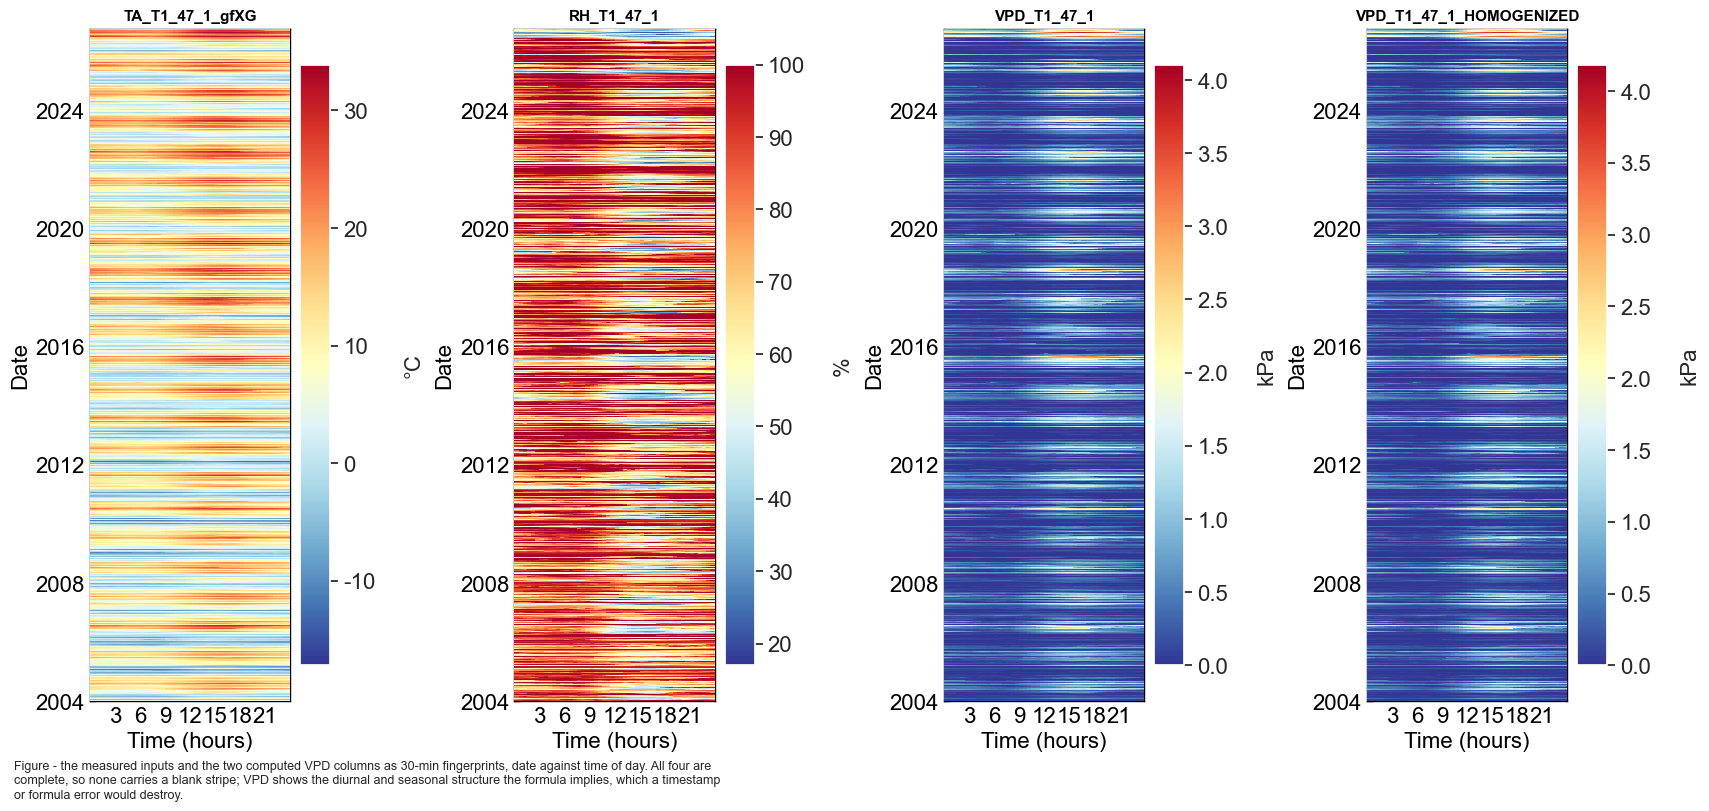

In [13]:
fig, axs = plt.subplots(ncols=4, figsize=(17, 8), dpi=100, layout='constrained')
for _ax, _col, _z, _dig in [(axs[0], TA_COL, '°C', 0),
                            (axs[1], RH_COL, '%', 0),
                            (axs[2], TARGET, 'kPa', 1),
                            (axs[3], TARGET_HOM, 'kPa', 1)]:
    dv.plotting.HeatmapDateTime(series=df[_col]).plot(
        ax=_ax, cb_digits_after_comma=_dig, zlabel=_z,
        format_style=dv.plotting.FormatStyle(title=_col, title_fontsize=11))
figcap(fig, "the measured inputs and the two computed VPD columns as 30-min fingerprints, date "
            "against time of day. All four are complete, so none carries a blank stripe; VPD shows "
            "the diurnal and seasonal structure the formula implies, which a timestamp or formula "
            "error would destroy.")

### 📊 Plot: median VPD by hour of day and by month

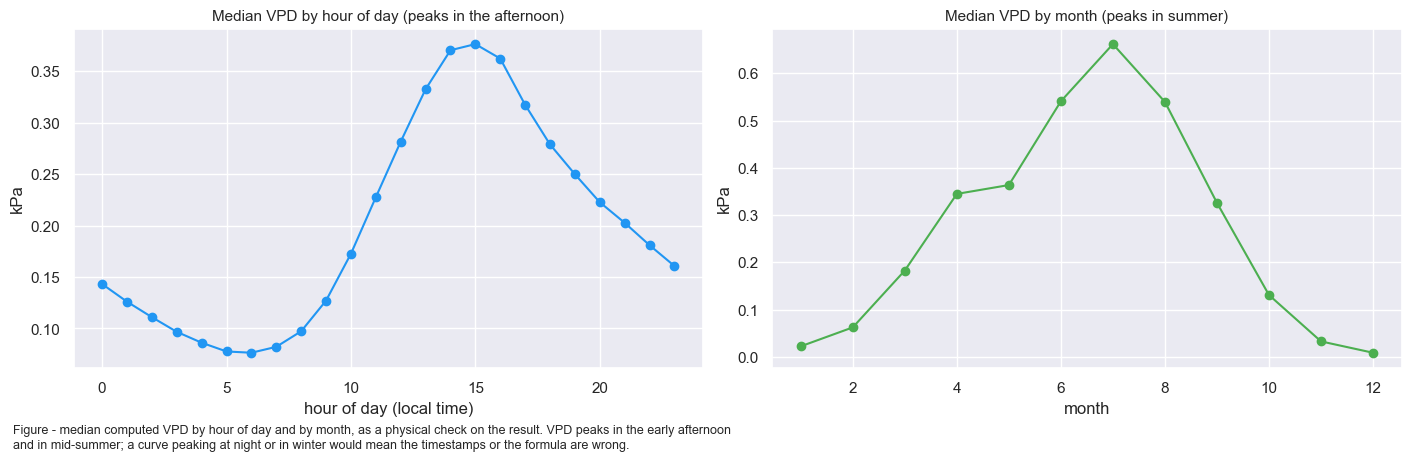

In [14]:
# Diurnal and seasonal behaviour of the computed VPD, as a second check that it is physical.
fig, axs = plt.subplots(ncols=2, figsize=(14, 4.5), dpi=100, layout='constrained')

_by_hour = df[TARGET].groupby(df.index.hour).median()
_by_hour.plot(ax=axs[0], marker='o', color='#2196F3')
axs[0].set_xlabel('hour of day (local time)')
axs[0].set_ylabel('kPa')
axs[0].set_title('Median VPD by hour of day (peaks in the afternoon)', fontsize=11)

_by_month = df[TARGET].groupby(df.index.month).median()
_by_month.plot(ax=axs[1], marker='o', color='#4CAF50')
axs[1].set_xlabel('month')
axs[1].set_ylabel('kPa')
axs[1].set_title('Median VPD by month (peaks in summer)', fontsize=11)
figcap(fig, "median computed VPD by hour of day and by month, as a physical check on the result. "
            "VPD peaks in the early afternoon and in mid-summer; a curve peaking at night or in "
            "winter would mean the timestamps or the formula are wrong.")

***

## 🔎 What the probe changes do to `VPD`

`TA` and `RH` come from **one probe**, and both change where the probe changes. In January 2016 the
two errors of the MP101A act on `VPD` in **opposition**: its `TA` reads about 1.3 °C too cold, which
lowers saturation vapour pressure and pulls `VPD` down, while its `RH` reads too dry, which pushes
`VPD` up. A basis that keeps both errors can therefore report a small step by cancellation, and a
basis that corrects only one of them a large one. Judging a basis by the size of its step alone
would select for the series that hides the most, so each basis is judged together with what it
corrects.

The reference is **MeteoSwiss Lägern**, 2.5 km away, whose own `TA` and `RH` give a reference `VPD`
by the same formula. The station lies about 400 m lower than the tower, so a constant offset between
the two series is expected and is not evidence; only the **change** in that offset across a probe
change is. Only records computed from two measurements (flag `0`) enter, and the residual is split
into day and night (sun above or below the horizon), because the shield terms of `02` act only in
sunlight.

**The two changes are not tested equally.**

- **January 2016 is an independent test.** `02` and `04` fitted their 2016 transfers against NABEL
  on the tower, never against Lägern.
- **June 2026 is not.** NABEL ends in 2018, so `02` and `04` fitted the HygroVUE10 transfers against
  Lägern, on the same two samples compared here. A small step of the homogenised basis at June 2026
  is therefore expected by construction and is reported, not counted as evidence. What the
  comparison does show is the size of the change in the measured series.

In [15]:
# Reference VPD from MeteoSwiss Laegern, by the same formula from that station's own TA and RH.
_ref = pd.read_parquet(REFPATH)[[REFCOL_TA, REFCOL_RH]].copy()
_ref.index = _ref.index - pd.Timedelta(minutes=15)   # TIMESTAMP_END -> TIMESTAMP_MID
_ref.index.name = df.index.name
_ref = _ref.dropna()
_ref['VPD_REF'] = dv.variables.calc_vpd_from_ta_rh(df=_ref, rh_col=REFCOL_RH, ta_col=REFCOL_TA)
check_vpd_range(_ref['VPD_REF'], 'VPD_REF (MeteoSwiss Laegern)')

BASES = {
    'measured TA and RH (VPD_T1_47_1)': TARGET,
    'homogenised TA and RH (VPD_T1_47_1_HOMOGENIZED)': TARGET_HOM,
    'homogenised TA, measured RH (version 3, diagnostic)': DIAG_MIXED,
}

# Purely measured records only, with their probe state and the day/night split.
_cmp = pd.concat([df.loc[flag == 0, list(BASES.values()) + [TA_SOURCECOL]],
                  DAY.rename('day'), _ref['VPD_REF']], axis=1, sort=False, join='inner').dropna()
_src, _yr = _cmp[TA_SOURCECOL], _cmp.index.year
print(f"\nComparison records: {len(_cmp):,}   {_cmp.index[0]} -> {_cmp.index[-1]}")


def residual(col):
    """Tower minus MeteoSwiss VPD, on the measured records only."""
    return _cmp[col] - _cmp['VPD_REF']

  VPD_REF (MeteoSwiss Laegern)       n=397,036  median 0.171  range 0.000..4.164 kPa

Comparison records: 381,892   2004-09-20 10:45:00 -> 2026-09-30 23:45:00


### 📋 Table: the step at January 2016

Each era is taken in one probe state only: the MP101A (code `1`) over the full years 2005-2015 and
the normal CS215 (code `0`) from 2017. 2016 belongs to neither era, and the later CS215 states and
the HygroVUE10 are left out of the CS215 sample, so no other change falls inside the comparison.
The step is judged against the **ordinary-year change**: the median absolute change of the same
residual between consecutive years outside the changeover, over full years only.

In [16]:
PRE_2016 = (_src == 1) & (_yr >= 2005)
POST_2016 = (_src == 0) & (_yr >= BREAK_YEAR + 1)
assert PRE_2016.sum() > 100_000 and POST_2016.sum() > 100_000, "too few records to judge the 2016 step"


def ordinary_change(res):
    """Median absolute change in the yearly mean residual between consecutive full years.

    Only the two eras' own records enter, so no later probe state sets the scale. The differences
    that span the changeover are dropped after differencing, rather than the years before it, so
    a 2015 -> 2017 gap cannot masquerade as one ordinary year-to-year change.
    """
    _r = res[(PRE_2016 | POST_2016)[res.index] & (res.index.year <= LAST_FULL_YEAR)]
    _d = _r.groupby(_r.index.year).mean().diff().abs()
    return float(_d.drop(index=[y for y in (BREAK_YEAR, BREAK_YEAR + 1) if y in _d.index]).median())


rows_2016, STEP_2016 = [], {}
for _label, _col in BASES.items():
    _res = residual(_col)
    _row = {'basis': _label}
    for _part, _sel in (('day', _cmp['day']), ('night', ~_cmp['day'])):
        _pre = _res[PRE_2016 & _sel].mean()
        _post = _res[POST_2016 & _sel].mean()
        STEP_2016[(_col, _part)] = _post - _pre
        _row[f'step {_part} (kPa)'] = round(_post - _pre, 4)
        _row[f'ordinary-year change {_part} (kPa)'] = round(ordinary_change(_res[_sel]), 4)
    rows_2016.append(_row)

tabcap("the step in the tower-minus-MeteoSwiss VPD residual from the MP101A (2005-2015) to the "
       "normal CS215 (from 2017), by day and by night, for each basis, against the median change "
       "of the same residual between ordinary consecutive years. Measured records only (flag 0). "
       "An independent test: no 2016 transfer was fitted against MeteoSwiss")
display(pd.DataFrame(rows_2016).set_index('basis'))

# The homogenised pair must be the most homogeneous of the three across 2016, day and night: it
# is the only basis that corrects both the temperature and the humidity of the MP101A. The basis of
# version 3 must be the least homogeneous, which is why it is no longer exported. Both are what the
# independent test found when this version was written; a change in 02 or 04 that undoes either
# fires here.
for _part in ('day', 'night'):
    _s = {c: abs(STEP_2016[(c, _part)]) for c in BASES.values()}
    assert _s[TARGET_HOM] <= _s[TARGET] and _s[TARGET_HOM] < _s[DIAG_MIXED], (
        f"{_part}: the homogenised pair is no longer the most homogeneous basis across 2016: {_s}")
    assert _s[DIAG_MIXED] == max(_s.values()), f"{_part}: the version-3 basis no longer steps most"
print("Across 2016 the homogenised pair steps least, day and night, and the version-3 basis most.")

Table - the step in the tower-minus-MeteoSwiss VPD residual from the MP101A (2005-2015) to the
normal CS215 (from 2017), by day and by night, for each basis, against the median change of the same
residual between ordinary consecutive years. Measured records only (flag 0). An independent test: no
2016 transfer was fitted against MeteoSwiss



,step day (kPa),ordinary-year change day (kPa),step night (kPa),ordinary-year change night (kPa)
basis,,,,
measured TA and RH (VPD_T1_47_1),-0.0023,0.0101,-0.0287,0.0071
homogenised TA and RH (VPD_T1_47_1_HOMOGENIZED),-0.0005,0.0129,-0.0140,0.0094
"homogenised TA, measured RH (version 3, diagnostic)",-0.0507,0.0145,-0.0510,0.0071


Across 2016 the homogenised pair steps least, day and night, and the version-3 basis most.


### 📊 Plot: the VPD residual against Lägern, by year

The yearly mean residual on each basis, by day and by night, over the full years only (a partial
2026 would be biased by season). Records of every probe state enter, so the later CS215 states show
in 2024 and 2025 as well.

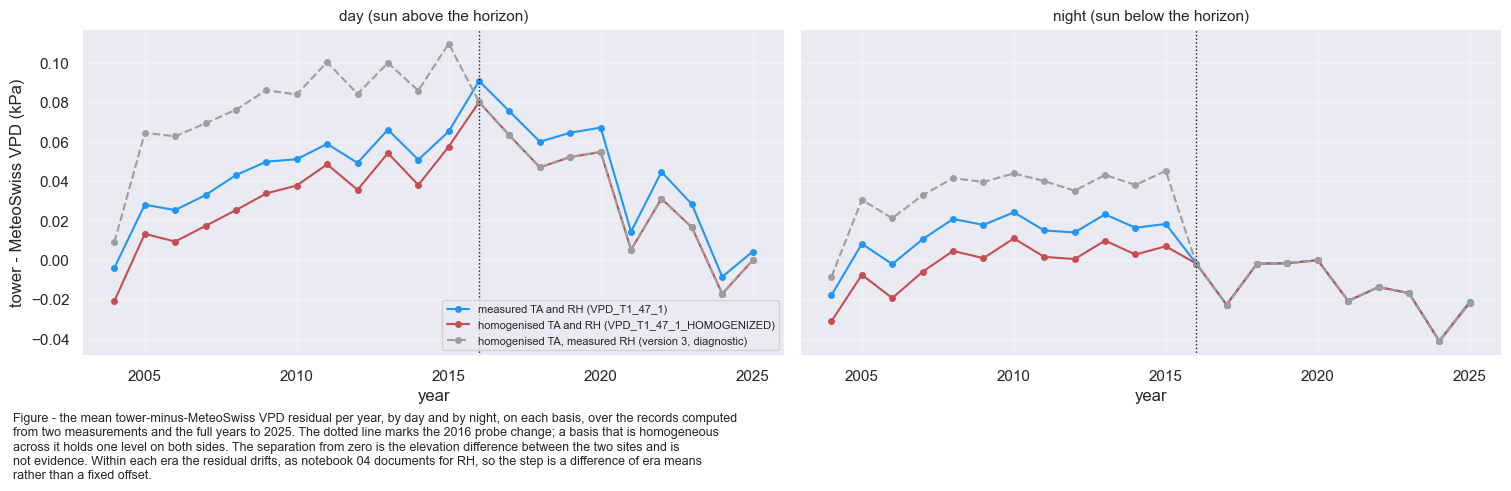

In [17]:
fig, axs = plt.subplots(ncols=2, figsize=(15, 4.8), dpi=100, layout='constrained', sharey=True)
_colours = dict(zip(BASES.values(), ('#2196F3', '#C44E52', '#9E9E9E')))
for _ax, _part, _sel in ((axs[0], 'day', _cmp['day']), (axs[1], 'night', ~_cmp['day'])):
    for _label, _col in BASES.items():
        _r = residual(_col)[_sel & (_yr <= LAST_FULL_YEAR)]
        _y = _r.groupby(_r.index.year).mean()
        _ax.plot(_y.index, _y.values, marker='o', ms=4, color=_colours[_col], label=_label,
                 ls='--' if _col == DIAG_MIXED else '-')
    _ax.axvline(BREAK_YEAR, color='k', ls=':', lw=1)
    _ax.set_title(f"{_part} (sun {'above' if _part == 'day' else 'below'} the horizon)", fontsize=11)
    _ax.set_xlabel('year')
    _ax.grid(alpha=.3)
axs[0].set_ylabel('tower - MeteoSwiss VPD (kPa)')
axs[0].legend(fontsize=8)
figcap(fig, f"the mean tower-minus-MeteoSwiss VPD residual per year, by day and by night, on each "
            f"basis, over the records computed from two measurements and the full years to "
            f"{LAST_FULL_YEAR}. The dotted line marks the {BREAK_YEAR} probe change; a basis that is "
            f"homogeneous across it holds one level on both sides. The separation from zero is the "
            f"elevation difference between the two sites and is not evidence. Within each era the residual "
            f"drifts, as notebook 04 documents for RH, so the step is a difference of era means "
            f"rather than a fixed offset.")

### 📋 Table: the step at June 2026

The HygroVUE10 from `HV_FIT_START` to the end of the record against the normal CS215 (code `0`) on
the same calendar dates of `HV_CS215_YEARS`, the two samples of `02` and `04`. One summer against
three, so the weather of summer 2026 enters the step as well as the probe. For the homogenised basis
this is **not** a test: the HygroVUE10 transfers of `02` and `04` were fitted against Lägern on these
samples.

In [18]:
_md = _cmp.index.month * 100 + _cmp.index.day
_lo, _hi = pd.Timestamp(HV_FIT_START), pd.Timestamp(PERIOD_END)
_window = (_md >= _lo.month * 100 + _lo.day) & (_md <= _hi.month * 100 + _hi.day)
HV_SAMPLE = (_src == 4) & (_cmp.index >= HV_FIT_START)
CS_SAMPLE = (_src == 0) & _yr.isin(HV_CS215_YEARS) & _window
assert HV_SAMPLE.sum() > 1000 and CS_SAMPLE.sum() > 1000, "too few records to compare the 2026 change"

rows_2026 = []
for _label, _col in BASES.items():
    _res = residual(_col)
    _row = {'basis': _label}
    for _part, _sel in (('day', _cmp['day']), ('night', ~_cmp['day'])):
        _row[f'step {_part} (kPa)'] = round(_res[HV_SAMPLE & _sel].mean() - _res[CS_SAMPLE & _sel].mean(), 4)
        _row[f'mean VPD {_part}, HygroVUE10 sample (kPa)'] = round(_cmp.loc[HV_SAMPLE & _sel, _col].mean(), 3)
    rows_2026.append(_row)

tabcap(f"the step in the tower-minus-MeteoSwiss VPD residual from the normal CS215 "
       f"({', '.join(map(str, HV_CS215_YEARS))}, {_lo:%d %b}-{_hi:%d %b}) to the HygroVUE10 "
       f"({_lo:%d %b %Y} to {_hi:%d %b %Y}), by day and by night, with the mean VPD of the "
       f"HygroVUE10 sample for scale. Measured records only (flag 0). Not an independent test of "
       f"the homogenised basis, whose transfers were fitted on these samples")
display(pd.DataFrame(rows_2026).set_index('basis'))

Table - the step in the tower-minus-MeteoSwiss VPD residual from the normal CS215 (2022, 2023, 2024,
12 Jun-30 Sep) to the HygroVUE10 (12 Jun 2026 to 30 Sep 2026), by day and by night, with the mean
VPD of the HygroVUE10 sample for scale. Measured records only (flag 0). Not an independent test of
the homogenised basis, whose transfers were fitted on these samples



,step day (kPa),"mean VPD day, HygroVUE10 sample (kPa)",step night (kPa),"mean VPD night, HygroVUE10 sample (kPa)"
basis,,,,
measured TA and RH (VPD_T1_47_1),0.0550,1.386,0.1171,1.107
homogenised TA and RH (VPD_T1_47_1_HOMOGENIZED),0.0209,1.333,0.0177,1.007
"homogenised TA, measured RH (version 3, diagnostic)",0.1076,1.419,0.1248,1.114


***

## ➡️ Prepare dataframe for export

In [19]:
VALCOL = TARGET           # VPD_T1_47_1 - a computed series, so no _gfXG suffix
VALCOL_HOM = TARGET_HOM   # VPD_T1_47_1_HOMOGENIZED
FLAGCOL = f"FLAG_{TARGET}_ISFILLED"
SOURCECOL = f"FLAG_{TARGET}_SOURCE"

# Two value columns and two flags, in the order of 02 and 04: measured, ISFILLED, homogenised,
# SOURCE. The version-3 basis is a diagnostic and is not exported. The SOURCE flag is carried over
# from 02/04 unchanged rather than rebuilt, since it is their statement about the probe.
export_df = pd.concat([df[VALCOL],
                       flag.astype(int).rename(FLAGCOL),
                       df[VALCOL_HOM],
                       df[TA_SOURCECOL].astype(int).rename(SOURCECOL)], axis=1)
export_df

,VPD_T1_47_1,FLAG_VPD_T1_47_1_ISFILLED,VPD_T1_47_1_HOMOGENIZED,FLAG_VPD_T1_47_1_SOURCE
TIMESTAMP_MIDDLE,,,,
2004-01-01 00:15:00,0.010534,6,0.010989,3
2004-01-01 00:45:00,0.014337,6,0.014478,3
2004-01-01 01:15:00,0.030081,6,0.026113,3
2004-01-01 01:45:00,0.034019,6,0.028659,3
2004-01-01 02:15:00,0.027493,6,0.024288,3
...,...,...,...,...
2026-09-30 21:45:00,1.076304,0,0.977429,4
2026-09-30 22:15:00,1.029250,0,0.929381,4
2026-09-30 22:45:00,0.988218,0,0.886749,4


Sanity check: both exported series must be complete, non-negative and physically plausible in kPa,
the index continuous 30MIN with no duplicates and ending at `PERIOD_END`, and every record must
carry both flags. `FLAG_VPD_T1_47_1_ISFILLED` holds only computed codes: `0` from two measurements,
`5`, `6` and `7` from a filled or reconstructed input.

In [20]:
print(f"Records:         {len(export_df):,}")
for _c in (VALCOL, VALCOL_HOM):
    print(f"{_c}: missing {int(export_df[_c].isna().sum())}, negative {int((export_df[_c] < 0).sum())}, "
          f"min/max {export_df[_c].min():.3f} / {export_df[_c].max():.3f} kPa")
print(f"Duplicate index: {export_df.index.duplicated().sum()}")
print(f"Index gaps:      "
      f"{(export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum()}")
print(f"Index:           {export_df.index[0]} -> {export_df.index[-1]}")

assert export_df.index[-1] == pd.Timestamp(PERIOD_END), f"the export ends at {export_df.index[-1]}"
for _c in (VALCOL, VALCOL_HOM):
    assert export_df[_c].notna().all(), f"{_c} is not complete"
    assert (export_df[_c] >= 0).all(), f"{_c}: VPD cannot be negative"
assert export_df[FLAGCOL].notna().all(), "a record has no flag"
assert export_df[FLAGCOL].isin(COMPUTED_FLAGS).all(), "every VPD record must be computed"
assert export_df[SOURCECOL].notna().all(), "a record has no SOURCE code"
assert set(export_df[SOURCECOL].unique()).issubset(set(SOURCE_LEGEND)), "unknown SOURCE code"

# Each column must be its own basis and not one of the others. Asserting on the values rather than
# on the variable names is what makes this catch a mis-wired export.
assert export_df[VALCOL].equals(df[TARGET]), "VPD_T1_47_1 is not the measured-pair series"
assert export_df[VALCOL_HOM].equals(df[TARGET_HOM]), "the homogenised column is not the homogenised pair"
assert not export_df[VALCOL_HOM].equals(df[DIAG_MIXED]), "the homogenised column is the version-3 basis"
print("\nSanity checks passed: both columns complete, non-negative, every record computed, each "
      "column built on its own pair.")

Records:         398,832
VPD_T1_47_1: missing 0, negative 0, min/max 0.000 / 4.104 kPa
VPD_T1_47_1_HOMOGENIZED: missing 0, negative 0, min/max 0.000 / 4.183 kPa
Duplicate index: 0
Index gaps:      0
Index:           2004-01-01 00:15:00 -> 2026-09-30 23:45:00

Sanity checks passed: both columns complete, non-negative, every record computed, each column built on its own pair.


### 📋 Table: VPD by year

`VPD` is weather, so the interannual spread of the yearly median should be small. Comparing the two
columns year by year shows where the homogenisation acts: before 2016, and from June 2026.
`measured_%` shows how much of each year rests on two genuine measurements. 2026 holds January to
September only and is labelled partial; its median is not comparable with the full years.

In [21]:
_yr_tab = pd.DataFrame({
    'count': export_df[VALCOL].groupby(export_df.index.year).size(),
    'median': export_df[VALCOL].groupby(export_df.index.year).median(),
    'median HOM': export_df[VALCOL_HOM].groupby(export_df.index.year).median(),
    'max': export_df[VALCOL].groupby(export_df.index.year).max(),
    'max HOM': export_df[VALCOL_HOM].groupby(export_df.index.year).max(),
    'measured_%': (100 * (export_df[FLAGCOL] == 0)).groupby(export_df.index.year).mean(),
    'reconstructed_RH_%': (100 * export_df[FLAGCOL].isin((6, 7))).groupby(export_df.index.year).mean(),
}).round(3)
_yr_tab['period'] = ['full year' if _y <= LAST_FULL_YEAR else
                     f"partial (Jan-{pd.Timestamp(PERIOD_END):%b})" for _y in _yr_tab.index]
tabcap("the exported VPD by year, on both bases: record count, median and maximum, the share computed "
       "from two measurements and the share resting on a reconstructed RH. The last year is partial")
display(_yr_tab)

_full = _yr_tab.loc[_yr_tab.index <= LAST_FULL_YEAR]
for _c in ('median', 'median HOM'):
    print(f"{_c:<11} yearly medians {_full[_c].min():.3f} to {_full[_c].max():.3f} kPa over the full years")

Table - the exported VPD by year, on both bases: record count, median and maximum, the share
computed from two measurements and the share resting on a reconstructed RH. The last year is partial



,count,median,median HOM,max,max HOM,measured_%,reconstructed_RH_%,period
TIMESTAMP_MIDDLE,,,,,,,,
2004,17568,0.169,0.139,2.714,2.813,28.017,71.983,full year
2005,17520,0.168,0.139,2.939,3.021,99.806,0.194,full year
2006,17520,0.179,0.147,3.309,3.432,99.846,0.154,full year
2007,17520,0.180,0.146,3.143,3.251,99.926,0.074,full year
2008,17568,0.181,0.151,2.351,2.432,99.886,0.114,full year
2009,17520,0.191,0.160,2.766,2.856,97.226,2.774,full year
2010,17520,0.139,0.114,2.857,2.930,99.035,0.965,full year
2011,17520,0.226,0.189,3.002,3.102,99.880,0.120,full year
2012,17568,0.173,0.143,3.075,3.189,92.811,7.172,full year


median      yearly medians 0.099 to 0.234 kPa over the full years
median HOM  yearly medians 0.098 to 0.217 kPa over the full years


### 📊 Plot: records per year not computed from two measurements

The block before 2005 is the period before the tower record, reconstructed from NABEL. The block
after 2018 is the loss of the NABEL humidity sensor, after which notebook `04` reconstructs `RH`
from MeteoSwiss Lägern.

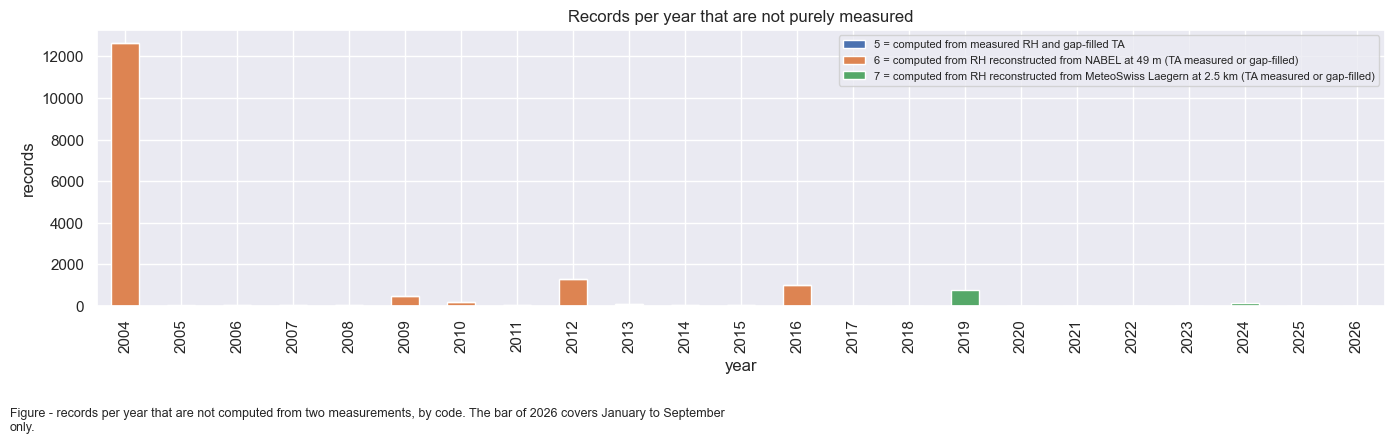

In [22]:
_tab = (pd.crosstab(export_df.index.year, export_df[FLAGCOL])
        .rename(columns=lambda f: FLAG_LEGEND.get(f, f))
        .rename_axis(index='year', columns=None))
_not_measured = _tab.drop(columns=[c for c in _tab.columns if str(c).startswith('0 =')],
                          errors='ignore')
ax = _not_measured.plot(kind='bar', stacked=True, figsize=(14, 4),
                        title='Records per year that are not purely measured')
ax.set_ylabel('records')
ax.legend(fontsize=8)
plt.tight_layout()
figcap(ax.get_figure(),
       f"records per year that are not computed from two measurements, by code. The bar of "
       f"{LAST_FULL_YEAR + 1} covers January to {pd.Timestamp(PERIOD_END):%B} only.")

### 📋 Table: records per year and provenance code

In [23]:
tabcap("records per year and provenance code, the counts behind the figure above")
display(_tab)

Table - records per year and provenance code, the counts behind the figure above



,0 = computed from measured TA and measured RH,5 = computed from measured RH and gap-filled TA,6 = computed from RH reconstructed from NABEL at 49 m (TA measured or gap-filled),7 = computed from RH reconstructed from MeteoSwiss Laegern at 2.5 km (TA measured or gap-filled)
year,,,,
2004,4922,0,12640,6
2005,17486,0,10,24
2006,17493,0,27,0
2007,17507,0,13,0
2008,17548,0,20,0
2009,17034,0,486,0
2010,17351,0,169,0
2011,17499,0,11,10
2012,16305,3,1260,0


***

## 💾 Save to file

In [24]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\07_METEO_VPD_2004-2026.09.parquet (0.129 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\07_METEO_VPD_2004-2026.09.parquet


### Verify the written file

Reading the parquet back and checking it directly, rather than trusting the in-memory frame.

In [25]:
_written = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"columns:   {list(_written.columns)}")
print(f"index:     {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")

assert list(_written.columns) == [VALCOL, FLAGCOL, VALCOL_HOM, SOURCECOL], \
    "unexpected columns in the written file"
assert len(_written) == len(export_df), "record count changed on write"
assert _written.index[-1] == pd.Timestamp(PERIOD_END), "the written file does not end at PERIOD_END"
for _c in (VALCOL, FLAGCOL, VALCOL_HOM, SOURCECOL):
    assert _written[_c].equals(export_df[_c]), f"{_c} differs from what was written"
check_vpd_range(_written[VALCOL], f"{VALCOL} (read back)")
check_vpd_range(_written[VALCOL_HOM], f"{VALCOL_HOM} (read back)")
print("\nWritten file verified.")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\07_METEO_VPD_2004-2026.09.parquet (0.013 seconds).

columns:   ['VPD_T1_47_1', 'FLAG_VPD_T1_47_1_ISFILLED', 'VPD_T1_47_1_HOMOGENIZED', 'FLAG_VPD_T1_47_1_SOURCE']
index:     2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)
  VPD_T1_47_1 (read back)            n=398,832  median 0.176  range 0.000..4.104 kPa
  VPD_T1_47_1_HOMOGENIZED (read back) n=398,832  median 0.157  range 0.000..4.183 kPa

Written file verified.


#### 📋 Table: yearly median of the written file

In [26]:
tabcap("the yearly median of both exported VPD columns, read back from the written parquet rather "
       "than taken from the frame in memory. The last year is partial")
display(_written[[VALCOL, VALCOL_HOM]].groupby(_written.index.year).median().round(3))

Table - the yearly median of both exported VPD columns, read back from the written parquet rather
than taken from the frame in memory. The last year is partial



,VPD_T1_47_1,VPD_T1_47_1_HOMOGENIZED
TIMESTAMP_MIDDLE,,
2004,0.169,0.139
2005,0.168,0.139
2006,0.179,0.147
2007,0.180,0.146
2008,0.181,0.151
2009,0.191,0.160
2010,0.139,0.114
2011,0.226,0.189
2012,0.173,0.143


***

## ⚠️ Note for downstream notebooks

Both `VPD` columns are **complete** and **fully computed**: every record follows from `TA` and `RH`
by the formula; no `VPD` model runs.

**Which column to use.**

- `VPD_T1_47_1` is the `VPD` the probe reported. It matches the measured `TA` and `RH` that enter
  EddyPro and the flux processing chain, and it is the column to pair with them, for example as a
  gap-filling or partitioning driver. It steps where the probe changed, in January 2016 and in
  June 2026, so it is not suited to trends or to comparisons across either date.
- `VPD_T1_47_1_HOMOGENIZED` puts every era onto the level of the normal CS215. Use it for anything
  that crosses January 2016 or June 2026. Its June 2026 transfer rests on one summer and is to be
  refitted with `02` and `04` once the record holds a winter.

`FLAG_VPD_T1_47_1_ISFILLED` tells a consumer what each record was computed from, for both columns:

- `0` — measured `TA` and measured `RH` at 47 m. The only records where nothing upstream was
  modelled or transferred.
- `5` — measured `RH`, with a `TA` that notebook `02` gap-filled. Skilful, but not two measurements.
- `6` — `RH` reconstructed from the NABEL sensor at 49 m (notebook `04`), ~3 % RH uncertainty.
- `7` — `RH` reconstructed from MeteoSwiss Lägern at 2.5 km (notebook `04`), a weaker transfer than
  `6`. Almost all after 2018.

`FLAG_VPD_T1_47_1_SOURCE` names the probe and its state, with the codes of `02` and `04`.

### The November 2019 outage

One block deserves naming. The 47 m humidity sensor was down from **4 November 2019 04:45 to
19 November 2019 23:45** — **759 consecutive records, 15.8 days**, over half that month, by far the
longest stretch after 2018 where the tower measured no `RH`. NABEL had ended by then, so notebook
`04` reconstructs it from MeteoSwiss Lägern: the `VPD` here is **computed from a Lägern-reconstructed
`RH`** and carries flag `7`, not modelled.

## End of notebook.

In [27]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-23 14:26:58
Finished: 2026-10-23 14:27:10
Runtime:  00:00:11 (hh:mm:ss)
